# PhishGuard: Intelligent Phishing URL Detection

## Introduction

PhishGuard is a URL classification project using the PhiUSIIL dataset. It studies URL text patterns and does not open the submitted websites.

## Objectives

- Explore the URL and label data.
- Create lexical and character-level TF-IDF features.
- Compare Logistic Regression, Linear SVM, and Random Forest.
- Use the saved LinearSVC pipeline to classify a custom URL.

## 1. Import Libraries and Set Up the Experiment

The libraries support data handling, plotting, feature creation, and model evaluation. The seed and sample settings make the experiment repeatable.

In [49]:
from pathlib import Path
from urllib.parse import urlsplit
import ipaddress
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, hstack
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MaxAbsScaler
from sklearn.svm import LinearSVC

RANDOM_STATE = 42
SAMPLE_SIZE = 30_000  # Set to None (or >= the dataset size) to use every row.
TEST_SIZE = 0.20
URL_COLUMN = "URL"
TARGET_COLUMN = "label"
LABEL_NAMES = {0: "Legitimate", 1: "Potential Phishing"}
DATA_PATH = Path.cwd() / "data" / "raw" / "phiusiil.csv"

print(f"Dataset path: {DATA_PATH.resolve()}")
print(f"Initial experiment sample size: {SAMPLE_SIZE}")

Dataset path: C:\Users\ASUS\OneDrive\Desktop\ML_Project\data\raw\phiusiil.csv
Initial experiment sample size: 30000


## 2. Load and Check the Dataset

The notebook reads the local CSV columns for URL and label. It checks for missing values and confirms the existing mapping: `0 = Legitimate` and `1 = Potential Phishing`.

In [50]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Local dataset not found at {DATA_PATH}. Run download_phiusiil.py once first."
    )

df = pd.read_csv(DATA_PATH, usecols=[URL_COLUMN, TARGET_COLUMN])
if df[[URL_COLUMN, TARGET_COLUMN]].isna().any().any():
    raise ValueError("URL or label contains missing values; inspect the CSV before training.")

df[TARGET_COLUMN] = pd.to_numeric(df[TARGET_COLUMN], errors="raise").astype("int8")
observed_labels = set(df[TARGET_COLUMN].unique())
if observed_labels != {0, 1}:
    raise ValueError(f"Expected already-converted internal labels {{0, 1}}, got {observed_labels}.")

print(f"Rows: {len(df):,}; columns loaded: {list(df.columns)}")
print("Verified mapping (not inverted again): 1 = phishing, 0 = legitimate")
print("Label counts:")
print(df[TARGET_COLUMN].map(LABEL_NAMES).value_counts())

Rows: 235,795; columns loaded: ['URL', 'label']
Verified mapping (not inverted again): 1 = phishing, 0 = legitimate
Label counts:
label
Legitimate            134850
Potential Phishing    100945
Name: count, dtype: int64


## 3. Understand the Dataset

The summary and plots compare the label counts and URL lengths. This gives a quick view of the data before feature extraction.

URL length summary:
                       count       mean        std   min   25%   50%   75%  \
label                                                                        
Legitimate          134850.0  27.228610   4.815612  16.0  24.0  27.0  30.0   
Potential Phishing  100945.0  46.238774  61.074850  14.0  26.0  34.0  48.0   

                       max  
label                       
Legitimate            58.0  
Potential Phishing  6097.0  


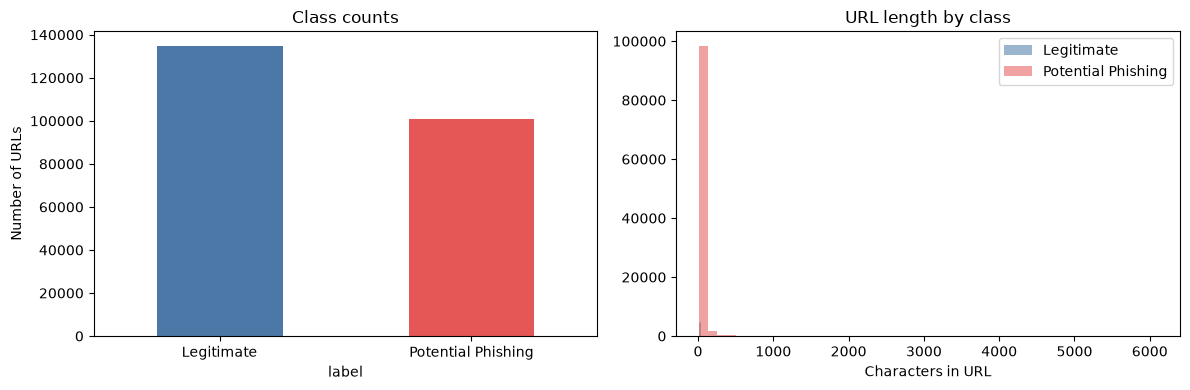

In [51]:
class_counts = df[TARGET_COLUMN].map(LABEL_NAMES).value_counts().reindex(
    ["Legitimate", "Potential Phishing"],
    fill_value=0
)
url_lengths = df[URL_COLUMN].astype(str).str.len()
eda_summary = pd.DataFrame({"url_length": url_lengths, "label": df[TARGET_COLUMN]})
print("URL length summary:")
print(eda_summary.groupby("label")["url_length"].describe().rename(index=LABEL_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts.plot(kind="bar", ax=axes[0], color=["#4c78a8", "#e45756"])
axes[0].set_title("Class counts")
axes[0].set_ylabel("Number of URLs")
axes[0].tick_params(axis="x", rotation=0)
for label, color in [(0, "#4c78a8"), (1, "#e45756")]:
    axes[1].hist(eda_summary.loc[eda_summary.label == label, "url_length"],
                 bins=50, alpha=0.55, label=LABEL_NAMES[label], color=color)
axes[1].set_title("URL length by class")
axes[1].set_xlabel("Characters in URL")
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Create the Train/Test Split

A stratified sample keeps the label proportions similar. The data is then split into training and test sets; the test set is held out for evaluation.

In [52]:
if SAMPLE_SIZE is None or SAMPLE_SIZE >= len(df):
    experiment_df = df.copy()
else:
    if SAMPLE_SIZE < 10:
        raise ValueError("SAMPLE_SIZE must be at least 10 for a stratified experiment.")
    experiment_df, _ = train_test_split(
        df,
        train_size=SAMPLE_SIZE,
        stratify=df[TARGET_COLUMN],
        random_state=RANDOM_STATE,
    )

X_urls = experiment_df[URL_COLUMN].astype(str).reset_index(drop=True)
y = experiment_df[TARGET_COLUMN].reset_index(drop=True)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_urls,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)
print(f"Experiment rows: {len(experiment_df):,}")
print(f"Train rows: {len(X_train_text):,}; test rows: {len(X_test_text):,}")
print("Training label proportions:")
print(y_train.value_counts(normalize=True).sort_index().rename(index=LABEL_NAMES))
print("Test label proportions:")
print(y_test.value_counts(normalize=True).sort_index().rename(index=LABEL_NAMES))

Experiment rows: 30,000
Train rows: 24,000; test rows: 6,000
Training label proportions:
label
Legitimate            0.571917
Potential Phishing    0.428083
Name: proportion, dtype: float64
Test label proportions:
label
Legitimate            0.571833
Potential Phishing    0.428167
Name: proportion, dtype: float64


## 5. Extract Lexical Features

These 22 numeric features describe URL text, such as its length, hostname, punctuation, path, and query string.

In [53]:
def extract_lexical_features(url):
    """Return numeric features computed only from one URL string."""
    text = "" if pd.isna(url) else str(url).strip()
    parse_text = text if "://" in text else f"//{text}"
    try:
        parsed = urlsplit(parse_text)
        host = parsed.hostname or ""
    except ValueError:
        parsed = urlsplit("")
        host = ""

    try:
        is_ip_address = int(bool(host) and ipaddress.ip_address(host) is not None)
    except ValueError:
        is_ip_address = 0

    length = max(len(text), 1)
    letters = sum(character.isalpha() for character in text)
    digits = sum(character.isdigit() for character in text)
    host_parts = [part for part in host.split(".") if part]
    try:
        has_port = int(parsed.port is not None)
    except ValueError:
        has_port = 0

    return {
        "url_length": len(text),
        "host_length": len(host),
        "num_letters": letters,
        "num_digits": digits,
        "digit_ratio": digits / length,
        "letter_ratio": letters / length,
        "num_dots": text.count("."),
        "num_hyphens": text.count("-"),
        "num_at_symbols": text.count("@"),
        "num_slashes": text.count("/"),
        "num_question_marks": text.count("?"),
        "num_equals": text.count("="),
        "num_ampersands": text.count("&"),
        "num_percent": text.count("%"),
        "num_underscores": text.count("_"),
        "num_subdomains": max(len(host_parts) - 2, 0),
        "has_https": int(parsed.scheme.casefold() == "https"),
        "has_ip_address": is_ip_address,
        "has_punycode": int("xn--" in host.casefold()),
        "has_port": has_port,
        "path_length": len(parsed.path),
        "query_length": len(parsed.query),
    }


lexical_train = pd.DataFrame(
    [extract_lexical_features(url) for url in X_train_text], index=X_train_text.index
)
lexical_test = pd.DataFrame(
    [extract_lexical_features(url) for url in X_test_text], index=X_test_text.index
)
print(f"Lexical feature count: {lexical_train.shape[1]}")
print(lexical_train.head())

Lexical feature count: 22
       url_length  host_length  num_letters  num_digits  digit_ratio  \
14010          38           30           33           0          0.0   
1690           28           20           22           0          0.0   
12346          28           20           23           0          0.0   
16464          19           11           14           0          0.0   
3239           26           18           21           0          0.0   

       letter_ratio  num_dots  num_hyphens  num_at_symbols  num_slashes  ...  \
14010      0.868421         2            0               0            2  ...   
1690       0.785714         2            1               0            2  ...   
12346      0.821429         2            0               0            2  ...   
16464      0.736842         2            0               0            2  ...   
3239       0.807692         2            0               0            2  ...   

       num_ampersands  num_percent  num_underscores  num_sub

## 6. Create Character-Level TF-IDF Features

Character n-grams represent short letter patterns in each URL. The vectorizer and scaler are fitted on training data only, then used to transform the test data.

In [54]:
vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=100_000,
    dtype=np.float32,
    sublinear_tf=True,
)
X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

lexical_scaler = MaxAbsScaler()
X_train_lexical_scaled = csr_matrix(
    lexical_scaler.fit_transform(lexical_train).astype(np.float32)
)
X_test_lexical_scaled = csr_matrix(
    lexical_scaler.transform(lexical_test).astype(np.float32)
)
X_train_combined = hstack([X_train_tfidf, X_train_lexical_scaled], format="csr")
X_test_combined = hstack([X_test_tfidf, X_test_lexical_scaled], format="csr")

print(f"TF-IDF train matrix: {X_train_tfidf.shape}; stored values: {X_train_tfidf.nnz:,}")
print(f"Combined train matrix: {X_train_combined.shape}; stored values: {X_train_combined.nnz:,}")

TF-IDF train matrix: (24000, 100000); stored values: 1,862,471
Combined train matrix: (24000, 100022); stored values: 2,071,930


## 7. Train and Compare the Models

Logistic Regression and Linear SVM use character-level TF-IDF with 22 lexical features. Random Forest uses the 22 lexical features only, so this is not an algorithm-only comparison. The held-out test set is evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.

A false positive is a legitimate URL predicted as phishing. A false negative is a phishing URL predicted as legitimate. In each confusion matrix, rows are actual classes and columns are predicted classes, ordered as `0 = Legitimate` and `1 = Potential Phishing`.

The reported metrics measure performance on the evaluated PhiUSIIL dataset split. They do not guarantee accuracy on unseen, real-world URLs. Treat predictions as indicators of potentially suspicious patterns, not definitive proof that a URL is safe or malicious.

The saved output below includes accuracy, each model's feature input, text confusion matrices, and the Linear SVM confusion-matrix plot. These are the recorded results for this experiment; rerunning the cell refits the three notebook comparison models but does not overwrite the saved deployment model.

Logistic Regression — positive class: Potential Phishing (label 1)
Feature input: Character TF-IDF + 22 lexical features
Accuracy: 0.9928 | Precision: 1.0000 | Recall: 0.9833 | F1: 0.9916 | ROC-AUC: 0.9990
Confusion matrix (rows=actual, columns=predicted; class order 0, 1):
[[3431    0]
 [  43 2526]]
Linear SVM — positive class: Potential Phishing (label 1)
Feature input: Character TF-IDF + 22 lexical features
Accuracy: 0.9955 | Precision: 1.0000 | Recall: 0.9895 | F1: 0.9947 | ROC-AUC: 0.9991
Confusion matrix (rows=actual, columns=predicted; class order 0, 1):
[[3431    0]
 [  27 2542]]


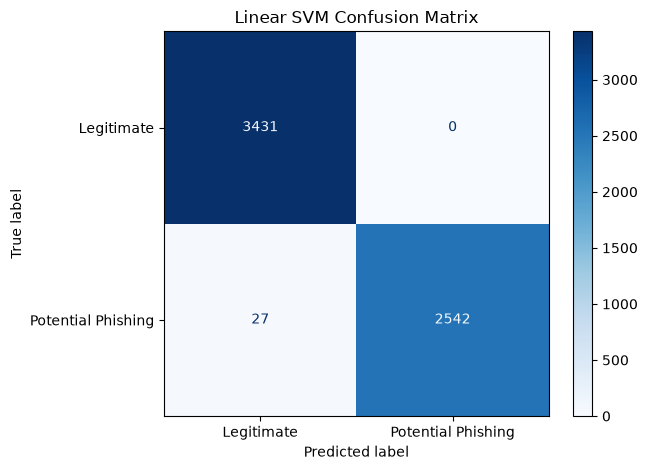

Random Forest (lexical only) — positive class: Potential Phishing (label 1)
Feature input: 22 lexical features only
Accuracy: 0.9945 | Precision: 0.9969 | Recall: 0.9903 | F1: 0.9936 | ROC-AUC: 0.9973
Confusion matrix (rows=actual, columns=predicted; class order 0, 1):
[[3423    8]
 [  25 2544]]
                                                       feature_input  \
model                                                                  
Linear SVM                    Character TF-IDF + 22 lexical features   
Random Forest (lexical only)                22 lexical features only   
Logistic Regression           Character TF-IDF + 22 lexical features   

                              accuracy  precision  recall      f1  roc_auc  
model                                                                       
Linear SVM                      0.9955     1.0000  0.9895  0.9947   0.9991  
Random Forest (lexical only)    0.9945     0.9969  0.9903  0.9936   0.9973  
Logistic Regression             0.

In [55]:
def evaluate_model(name, model, X_eval, y_true, score_values, feature_input):
    """Print the requested test metrics and return one summary row."""
    predictions = model.predict(X_eval)
    accuracy = accuracy_score(y_true, predictions)
    precision = precision_score(y_true, predictions, pos_label=1, zero_division=0)
    recall = recall_score(y_true, predictions, pos_label=1, zero_division=0)
    f1 = f1_score(y_true, predictions, pos_label=1, zero_division=0)
    auc = roc_auc_score(y_true, score_values) if y_true.nunique() == 2 else np.nan
    matrix = confusion_matrix(y_true, predictions, labels=[0, 1])
    print(f"{name} — positive class: {LABEL_NAMES[1]} (label 1)")
    print(f"Feature input: {feature_input}")
    print(
        f"Accuracy: {accuracy:.4f} | Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | F1: {f1:.4f} | ROC-AUC: {auc:.4f}"
    )
    print("Confusion matrix (rows=actual, columns=predicted; class order 0, 1):")
    print(matrix)

    if name == "Linear SVM":
        display = ConfusionMatrixDisplay(
            confusion_matrix=matrix,
            display_labels=[LABEL_NAMES[0], LABEL_NAMES[1]],
        )
        display.plot(cmap="Blues", values_format="d")
        display.ax_.set_title("Linear SVM Confusion Matrix")
        plt.tight_layout()
        plt.show()

    return {
        "model": name,
        "feature_input": feature_input,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc,
    }


results = []
models = {}

logistic_model = LogisticRegression(
    C=2.0,
    solver="liblinear",
    max_iter=500,
    random_state=RANDOM_STATE,
)
logistic_model.fit(X_train_combined, y_train)
models["logistic_regression"] = logistic_model
logistic_scores = logistic_model.predict_proba(X_test_combined)[:, 1]
results.append(
    evaluate_model(
        "Logistic Regression",
        logistic_model,
        X_test_combined,
        y_test,
        logistic_scores,
        "Character TF-IDF + 22 lexical features",
    )
)

svm_model = LinearSVC(C=1.0, max_iter=2_000, random_state=RANDOM_STATE)
svm_model.fit(X_train_combined, y_train)
models["linear_svm"] = svm_model
svm_scores = svm_model.decision_function(X_test_combined)
results.append(
    evaluate_model(
        "Linear SVM",
        svm_model,
        X_test_combined,
        y_test,
        svm_scores,
        "Character TF-IDF + 22 lexical features",
    )
)

rf_model = RandomForestClassifier(
    n_estimators=120,
    max_depth=18,
    min_samples_leaf=2,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf_model.fit(lexical_train, y_train)
models["random_forest"] = rf_model
rf_scores = rf_model.predict_proba(lexical_test)[:, 1]
results.append(
    evaluate_model(
        "Random Forest (lexical only)",
        rf_model,
        lexical_test,
        y_test,
        rf_scores,
        "22 lexical features only",
    )
)

results_df = pd.DataFrame(results).set_index("model")
print(results_df.sort_values("f1", ascending=False).round(4))

## 8. Test a Custom URL

This cell loads the saved model bundle, so it does not need the notebook's training cells. The shared pipeline normalizes the URL and applies the fitted TF-IDF vectorizer and scaler. The example output is an unverified model demonstration, not a ground-truth label. The result is a class label, not a probability.

In [56]:
from pathlib import Path

import joblib

from phishguard_pipeline import normalize_url, transform_urls

MODEL_PATH = Path.cwd() / "models" / "phishing_model.joblib"
if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Saved model not found at {MODEL_PATH}. Run this notebook from the project root."
    )

model_bundle = joblib.load(MODEL_PATH)
estimator = model_bundle["estimator"]
vectorizer = model_bundle["vectorizer"]
lexical_scaler = model_bundle["lexical_scaler"]
label_names = {int(label): name for label, name in model_bundle["label_mapping"].items()}

def predict_url(url):
    """Predict one URL with the saved LinearSVC and fitted preprocessing."""
    try:
        url_text = normalize_url(url)
    except ValueError as error:
        return {"error": f"Invalid URL: {error}"}

    features = transform_urls([url_text], vectorizer, lexical_scaler)
    if features.shape[1] != estimator.n_features_in_:
        raise ValueError(
            f"Feature count mismatch: expected {estimator.n_features_in_}, "
            f"got {features.shape[1]}."
        )
    prediction = int(estimator.predict(features)[0])
    return {
        "url": url_text,
        "prediction": label_names[prediction],
        "label": prediction,
    }


# Replace this example with a URL you want to test.
url_to_check = "https://example.com/login"
predict_url(url_to_check)

{'url': 'https://example.com/login',
 'prediction': 'Potential Phishing',
 'label': 1}

## 9. Conclusion

This project uses lexical URL features and character-level TF-IDF to compare Logistic Regression, Linear SVM, and Random Forest. The saved LinearSVC workflow applies the shared preprocessing pipeline to a custom URL and returns a class label.

Predictions are indicators of suspicious patterns, not proof that a URL is malicious or safe. Results on this dataset do not guarantee performance on unseen, real-world URLs.